# QAOA on constrained airline QUBOs

An optional quantum-circuit extension to the classical airline-recovery pipeline. Four actual residual neighborhoods are selected by structural size before algorithm outcomes. Exact references, thermal annealing and uniform sampling share the same QUBOs, 1,024 final samples and repair policy.

In [2]:
import pandas as pd
from IPython.display import display, SVG
from bootstrap import ROOT
from qaoa_experiment import run_experiment, summarize
print("Execution: ideal statevector optimization, finite-shot final sampling, independent Qiskit verification")
from case_catalog import load_cases
from measurements import compile_case
from qaoa_core import QUBOStatevector
_, cases = load_cases()
example_model = QUBOStatevector(compile_case(cases[0][1]).bqm, 16)
print("PHYSICAL QUBO AS A SPARSE PAULI HAMILTONIAN, INCLUDING OFFSET")
display(example_model.hamiltonian())

Execution: ideal statevector optimization, finite-shot final sampling, independent Qiskit verification
PHYSICAL QUBO AS A SPARSE PAULI HAMILTONIAN, INCLUDING OFFSET


SparsePauliOp(['IIIIIIII', 'IIIIIIIZ', 'IIIIIIZI', 'IIIIIZII', 'IIIIZIII', 'IIIZIIII', 'IIZIIIII', 'IZIIIIII', 'ZIIIIIII', 'IIIIIIZZ', 'IIIIIZIZ', 'IIIIZIIZ', 'IIIZIIZI', 'IIZIIZII', 'IZIIIIIZ', 'IZIIIZII', 'ZIIIIIIZ', 'ZIIIIIZI'],
              coeffs=[132.84990108+0.j, -33.7173502 +0.j, -17.07730904+0.j, -17.04902894+0.j,
  -5.        +0.j,  -5.        +0.j,  -5.        +0.j, -16.66873763+0.j,
 -16.66873763+0.j,  16.66873763+0.j,  16.66873763+0.j,  16.66873763+0.j,
  16.66873763+0.j,  16.66873763+0.j,  16.66873763+0.j,  16.66873763+0.j,
  16.66873763+0.j,  16.66873763+0.j])

## Hamiltonian and validation

For the parent QUBO, dimod uses $s=2x-1$ while $Z=1-2x$. Thus
$$H_C=cI-\sum_i h_i Z_i+\sum_{ij}J_{ij}Z_iZ_j.$$

RZ/RZZ cost layers pair with X mixers or disjoint one-choice projectors plus slack-X mixing. The latter preserves one route/dummy per PNR; capacities remain in the QUBO. Analytic adjoint gradients are independently checked. Depths 1–5 use multistart optimization and continuation; the finite gamma search window is not a universal periodicity assumption.

In [3]:
report = run_experiment(ROOT / "artifacts/notebook")
print("RAW SAMPLES AND COMMON REPAIR — MEANS OVER CASES AND SEEDS")
display(summarize(report))
print("EXACT LOCAL REFERENCES AND QUBO RESOURCES")
display(pd.DataFrame([{ "case": c["case"], "qubits": c["qubits"], "PNRs": c["pnrs"], "couplers": c["resources"]["couplers"], "exact_S3": c["reference"]["objective"] } for c in report["cases"]]))

actual_01: 8 qubits, exact reference + random/SA/QAOA depths [1, 2, 3, 4, 5] completed


actual_02: 9 qubits, exact reference + random/SA/QAOA depths [1, 2, 3, 4, 5] completed


actual_03: 12 qubits, exact reference + random/SA/QAOA depths [1, 2, 3, 4, 5] completed


actual_04: 13 qubits, exact reference + random/SA/QAOA depths [1, 2, 3, 4, 5] completed


Matplotlib is building the font cache; this may take a moment.


RAW SAMPLES AND COMMON REPAIR — MEANS OVER CASES AND SEEDS


,backend,runs,raw_strict_feasible_fraction,raw_physical_feasible_fraction,raw_ground_fraction,raw_best_physical_objective_gap,seconds,raw_physical_sample_runs,raw_reference_hit_runs,repaired_reference_hits
0,uniform,20,0.010498,0.041406,0.001563,0.004513,0.000622,20,18,18
1,onehot_uniform,20,0.105811,0.489600,0.015283,0.000000,0.000366,20,20,20
2,neal,20,0.991895,0.992969,0.303467,0.000000,0.043889,20,20,20
3,qaoa_p1,20,0.047314,0.142578,0.008496,0.000000,0.030808,20,20,20
4,qaoa_p2,20,0.071875,0.171484,0.012012,0.000000,0.098498,20,20,20
5,qaoa_p3,20,0.116016,0.241748,0.022266,0.000000,0.230498,20,20,20
6,qaoa_p4,20,0.201025,0.319971,0.036816,0.000000,0.417456,20,20,20
7,qaoa_p5,20,0.242139,0.364453,0.042871,0.457802,0.821456,20,19,19
8,qaoa_onehot_p1,20,0.306885,0.715967,0.047803,0.000000,0.040006,20,20,20
9,qaoa_onehot_p2,20,0.383447,0.716699,0.108545,0.000000,0.101941,20,20,20


EXACT LOCAL REFERENCES AND QUBO RESOURCES


,case,qubits,PNRs,couplers,exact_S3
0,actual_01,8,3,9,11.577725
1,actual_02,9,3,19,11.265996
2,actual_03,12,3,27,11.470396
3,actual_04,13,3,39,11.228794


## Scope

Raw physical feasibility, slack feasibility and optimal-state sampling are distinct. Classical repair and global admission are audited separately. Independent local patches cannot be added together. The parent allocation remains classical. Circuit resources assume all-to-all connectivity; no hardware, noise, speedup or industry-outperformance result is claimed.

GLOBAL PATCH ADMISSION AGAINST THE FIXED PUBLISHED INCUMBENT


,case,backend,accepted,global_PNRs,global_passengers,violations
0,actual_01,uniform,False,5523,7239,0
1,actual_01,onehot_uniform,False,5523,7239,0
2,actual_01,neal,False,5523,7239,0
3,actual_01,qaoa_p1,False,5523,7239,0
4,actual_01,qaoa_p2,False,5523,7239,0
5,actual_01,qaoa_p3,False,5523,7239,0
6,actual_01,qaoa_p4,False,5523,7239,0
7,actual_01,qaoa_p5,False,5523,7239,0
8,actual_01,qaoa_onehot_p1,False,5523,7239,0
9,actual_01,qaoa_onehot_p2,False,5523,7239,0


END-TO-END EXPERIMENT TIMING


,end_to_end_seconds,python,system,architecture,requested_blas_threads,scope
0,76.137301,3.11.18,Darwin,arm64,1,"Frozen-case loading, all exact/random/SA/QAOA ..."


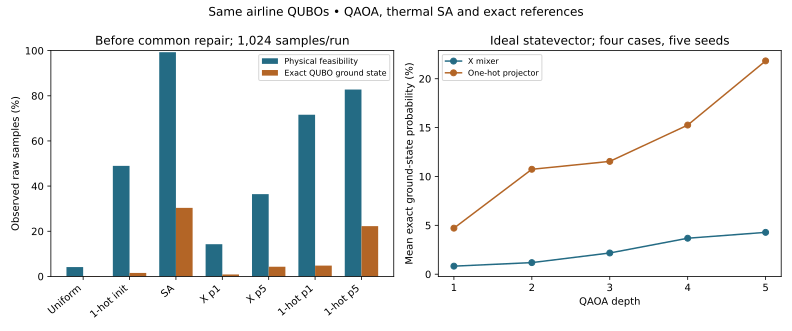

Executable example circuit: artifacts/notebook/example_qaoa.qasm


In [4]:
print("GLOBAL PATCH ADMISSION AGAINST THE FIXED PUBLISHED INCUMBENT")
display(pd.DataFrame([{ "case": r["case"], "backend": r["backend"], "accepted": r["accepted"], "global_PNRs": r["admitted"]["assigned_pnrs"], "global_passengers": r["admitted"]["assigned_passengers"], "violations": r["admitted"]["capacity_violations"] } for r in report["global_patch_audits"]]))
print("END-TO-END EXPERIMENT TIMING")
display(pd.DataFrame([report["timing"]]))
display(SVG(filename=str(ROOT / "artifacts/notebook/qaoa_comparison.svg")))
print("Executable example circuit: artifacts/notebook/example_qaoa.qasm")